# RadioSkySims — Mapas do Céu

Fluxo de exemplo do bounded context **SkyMap** (`radioskysims-skymap`):
geração de mapas HEALPix (sintético offline + PySM3), operações
(suavização/máscara), análise (estatística + espectro angular Cℓ) e I/O (FITS).

A visualização é Mollweide via HEALPy, com figuras salvas em `plots/`.


## API unificada — `SkyMapManager`

Para uniformizar a experiência do usuário, o pacote `radioskysims-skymap`
expõe uma fachada de conveniência (`SkyMapManager` + `SkyMapHandle`),
pensada para notebooks e scripts exploratórios:

```python
from radioskysims_skymap import SkyMapManager

map = SkyMapManager.create_map_from_coefficients(cls, nside=64, seed=42)
map = SkyMapManager.load_map_from_file("mapa.fits")
map = SkyMapManager.download(survey_id=..., ra_deg=..., dec_deg=..., fov_deg=..., nside=64)
noise_map = SkyMapManager.create_noise_map(method="pysm", nside=64, freq_ghz=1.0)

map.smooth(fwhm_deg=5.0).rotate(rot_deg=(0, 0, 0)).mask(mask).view()
map.change_coordinates("equatorial")
map.save_to_file("mapa.fits", format="fits")
map.compute_power_spectrum()
map.compute_statistics()
map.register("meu-mapa")
```

As seções 1–6 abaixo mostram o fluxo "de baixo nível" (domínio +
infraestrutura diretamente), útil para entender a arquitetura. A
**Seção 7** mostra o mesmo fluxo, de ponta a ponta, usando somente a
API unificada.


## 1. Parâmetros de referência


<img src='data:image/png;base64,iVBORw0KGgoAAAANSUhEUgAAAEAAAABACAYAAACqaXHeAAAABHNCSVQICAgIfAhkiAAAAAlwSFlz
AAAB+wAAAfsBxc2miwAAABl0RVh0U29mdHdhcmUAd3d3Lmlua3NjYXBlLm9yZ5vuPBoAAA6zSURB
VHic7ZtpeFRVmsf/5966taWqUlUJ2UioBBJiIBAwCZtog9IOgjqACsogKtqirT2ttt069nQ/zDzt
tI4+CrJIREFaFgWhBXpUNhHZQoKBkIUASchWla1S+3ar7r1nPkDaCAnZKoQP/D7mnPOe9/xy76n3
nFSAW9ziFoPFNED2LLK5wcyBDObkb8ZkxuaoSYlI6ZcOKq1eWFdedqNzGHQBk9RMEwFAASkk0Xw3
ETacDNi2vtvc7L0ROdw0AjoSotQVkKSvHQz/wRO1lScGModBFbDMaNRN1A4tUBCS3lk7BWhQkgpD
lG4852/+7DWr1R3uHAZVQDsbh6ZPN7CyxUrCzJMRouusj0ipRwD2uKm0Zn5d2dFwzX1TCGhnmdGo
G62Nna+isiUqhkzuKrkQaJlPEv5mFl2fvGg2t/VnzkEV8F5ioioOEWkLG86fvbpthynjdhXYZziQ
x1hC9J2NFyi8vCTt91Fh04KGip0AaG9zuCk2wQCVyoNU3Hjezee9bq92duzzTmxsRJoy+jEZZZYo
GTKJ6SJngdJqAfRzpze0+jHreUtPc7gpBLQnIYK6BYp/uGhw9YK688eu7v95ysgshcg9qSLMo3JC
4jqLKQFBgdKDPoQ+Pltb8dUyQLpeDjeVgI6EgLIQFT5tEl3rn2losHVsexbZ3EyT9wE1uGdkIPcy
BGxn8QUq1QrA5nqW5i2tLqvrrM9NK6AdkVIvL9E9bZL/oyfMVd/jqvc8LylzRBKDJSzIExwhQzuL
QYGQj4rHfFTc8mUdu3E7yoLtbTe9gI4EqVgVkug2i5+uXGo919ixbRog+3fTbQ8qJe4ZOYNfMoTI
OoshUNosgO60AisX15aeI2PSIp5KiFLI9ubb1vV3Qb2ltwLakUCDAkWX7/nHKRmmGIl9VgYsUhJm
2NXjKYADtM1ygne9QQDIXlk49FBstMKx66D1v4+XuQr7vqTe0VcBHQlRWiOCbmmSYe2SqtL6q5rJ
zsTb7lKx3FKOYC4DoqyS/B5bvLPxvD9Qtf6saxYLQGJErmDOdOMr/zo96km1nElr8bmPOBwI9COv
HnFPRIwmkSOv9kcAS4heRsidOkpeWBgZM+UBrTFAXNYL5Vf2ii9c1trNzpYdaoVil3WIc+wdk+gQ
noie3ecCcxt9ITcLAPWt/laGEO/9U6PmzZkenTtsSMQ8uYywJVW+grCstAvCIaAdArAsIWkRDDs/
KzLm2YcjY1Lv0UdW73HabE9n6V66cxSzfEmuJssTpKGVp+0vHq73FwL46eOjpMpbRAnNmJFrGJNu
Ukf9Yrz+3rghiumCKNXXWPhLYcjxGsIpoCMsIRoFITkW8AuyM8jC1+/QLx4bozCEJIq38+1rtpR6
V/yzb8eBlRb3fo5l783N0CWolAzJHaVNzkrTzlEp2bQ2q3TC5gn6wpnoQAmwSiGh2GitnTmVMc5O
UyfKWUKCIsU7+fZDKwqdT6DDpvkzAX4/+AMFjk0tDp5GRXLpQ2MUmhgDp5gxQT8+Y7hyPsMi8uxF
71H0oebujHALECjFKaW9Lm68n18wXp2kVzIcABytD5iXFzg+WVXkegpAsOOYziqo0OkK76GyquC3
ltZAzMhhqlSNmmWTE5T6e3IN05ITFLM4GdN0vtZ3ob8Jh1NAKXFbm5PtLU/eqTSlGjkNAJjdgn/N
aedXa0tdi7+t9G0FIF49rtMSEgAs1kDLkTPO7ebm4IUWeyh1bKomXqlgMG6kJmHcSM0clYLJ8XtR
1GTnbV3F6I5wCGikAb402npp1h1s7LQUZZSMIfALFOuL3UUrfnS8+rez7v9qcold5tilgHbO1fjK
9ubb17u9oshxzMiUBKXWqJNxd+fqb0tLVs4lILFnK71H0Ind7uiPgACVcFJlrb0tV6DzxqqTIhUM
CwDf1/rrVhTa33/3pGPxJYdQ2l2cbgVcQSosdx8uqnDtbGjh9SlDVSMNWhlnilfqZk42Th2ZpLpf
xrHec5e815zrr0dfBZSwzkZfqsv+1FS1KUknUwPARVvItfKUY+cn57yP7qv07UE3p8B2uhUwLk09
e0SCOrK+hbdYHYLjRIl71wWzv9jpEoeOHhGRrJAzyEyNiJuUqX0g2sBN5kGK6y2Blp5M3lsB9Qh4
y2Ja6x6+i0ucmKgwMATwhSjdUu49tKrQ/pvN5d53ml2CGwCmJipmKjgmyuaXzNeL2a0AkQ01Th5j
2DktO3Jyk8f9vcOBQHV94OK+fPumJmvQHxJoWkaKWq9Vs+yUsbq0zGT1I4RgeH2b5wef7+c7bl8F
eKgoHVVZa8ZPEORzR6sT1BzDUAD/d9F78e2Tzv99v8D+fLVTqAKAsbGamKey1Mt9Ann4eH3gTXTz
idWtAJ8PQWOk7NzSeQn/OTHDuEikVF1R4z8BQCy+6D1aWRfY0tTGG2OM8rRoPaeIj5ZHzJxszElN
VM8K8JS5WOfv8mzRnQAKoEhmt8gyPM4lU9SmBK1MCQBnW4KONT86v1hZ1PbwSXPw4JWussVjtH9Y
NCoiL9UoH/6PSu8jFrfY2t36erQHXLIEakMi1SydmzB31h3GGXFDFNPaK8Rme9B79Ixrd0WN+1ij
NRQ/doRmuFLBkHSTOm5GruG+pFjFdAmorG4IXH1Qua6ASniclfFtDYt+oUjKipPrCQB7QBQ2lrgP
fFzm+9XWUtcqJ3/5vDLDpJ79XHZk3u8nGZ42qlj1+ydtbxysCezrydp6ugmipNJ7WBPB5tydY0jP
HaVNzs3QzeE4ZpTbI+ZbnSFPbVOw9vsfnVvqWnirPyCNGD08IlqtYkh2hjZ5dErEQzoNm+6ykyOt
Lt5/PQEuSRRKo22VkydK+vvS1XEKlhCJAnsqvcVvH7f/ZU2R67eXbMEGAMiIV5oWZWiWvz5Fv2xG
sjqNJQRvn3Rs2lji/lNP19VjAQDgD7FHhujZB9OGqYxRkZxixgRDVlqS6uEOFaJUVu0rPFzctrnF
JqijImVp8dEKVWyUXDk92zAuMZ6bFwpBU1HrOw6AdhQgUooChb0+ItMbWJitSo5Ws3IAOGEOtL53
0vHZih9sC4vtofZ7Qu6523V/fmGcds1TY3V36pUsBwAbSlxnVh2xLfAD/IAIMDf7XYIkNmXfpp2l
18rkAJAy9HKFaIr/qULkeQQKy9zf1JgDB2uaeFNGijo5QsUyacNUUTOnGO42xSnv4oOwpDi1zYkc
efUc3I5Gk6PhyTuVKaOGyLUAYPGIoY9Pu/atL/L92+4q9wbflRJ2Trpm/jPjdBtfnqB/dIThcl8A
KG7hbRuKnb8qsQsVvVlTrwQAQMUlf3kwJI24Z4JhPMtcfng5GcH49GsrxJpGvvHIaeem2ma+KSjQ
lIwUdYyCY8j4dE1KzijNnIP2llF2wcXNnsoapw9XxsgYAl6k+KzUXbi2yP3KR2ecf6z3BFsBICdW
nvnIaG3eHybqX7vbpEqUMT+9OL4Qpe8VON7dXuFd39v19FoAABRVePbGGuXTszO0P7tu6lghUonE
llRdrhArLvmKdh9u29jcFiRRkfLUxBiFNiqSU9icoZQHo5mYBI1MBgBH6wMNb+U7Pnw337H4gi1Y
ciWs+uks3Z9fztUvfzxTm9Ne8XXkvQLHNytOOZeiD4e0PgkAIAYCYknKUNUDSXEKzdWNpnil7r4p
xqkjTarZMtk/K8TQ6Qve78qqvXurGwIJqcOUKfUWHsm8KGvxSP68YudXq4pcj39X49uOK2X142O0
Tz5/u/7TVybqH0rSya6ZBwD21/gubbrgWdDgEOx9W
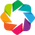

NSide=64 → 49152 pixels | freq=1.0 GHz | frame=galactic


In [1]:
# ── Parâmetros de referência para mapas do céu ──
from pathlib import Path

import healpy as hp
import matplotlib.pyplot as plt
import numpy as np
from radioskysims_viz import save_figure

# Resolução HEALPix (potência de 2) e frequência de referência.
NSIDE = 64  # → 49152 pixels
FREQ_GHZ = 1.0  # 1 GHz (banda L) — usado nos metadados/PySM
FRAME = "galactic"  # galactic | equatorial | ecliptic
SEED = 42

DATA_DIR = Path("data")
SKYMAP_DIR = DATA_DIR / "skymap"
SKYMAP_DIR.mkdir(parents=True, exist_ok=True)
print(f"NSide={NSIDE} → {hp.nside2npix(NSIDE)} pixels | freq={FREQ_GHZ} GHz | frame={FRAME}")


## 2. Mapa sintético (offline) — geração e visualização

Campo aleatório com espectro tipo-físico (`Cℓ ∝ ℓ^{-3/2}`) via `hp.synfast` — determinístico (seed) e sem rede.


salvo: /media/barosi/RadioSkySimSuite/notebooks/plots/skymap_analytic.png


PosixPath('plots/skymap_analytic.png')

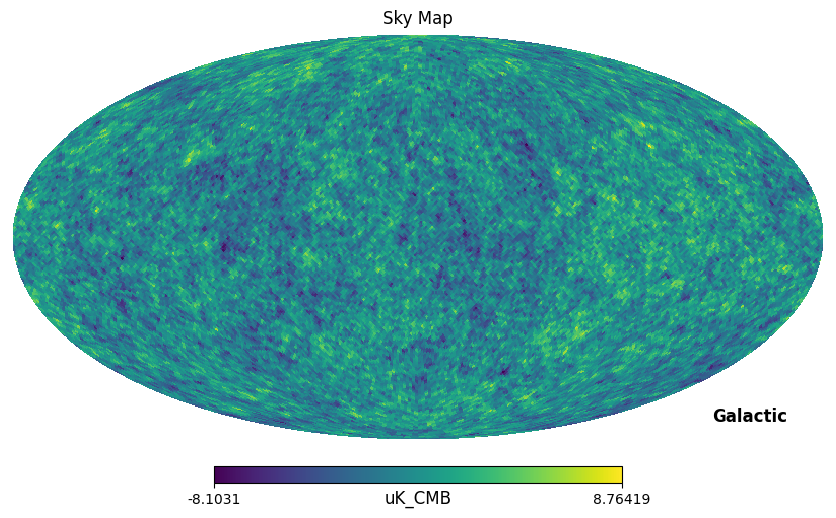

In [2]:
# Mapa sintético OFFLINE: campo gaussiano com espectro de potência dado.
from radioskysims_skymap.domain.skymap.factory import SkyMapFactory
from radioskysims_skymap.infrastructure.skymap.visualization import SkyMapVisualizer

rng = np.random.default_rng(SEED)
ell = np.arange(3, 200)
cls_input = 1.0 * ell**-1.5  # ~ Cℓ ∝ ℓ^{-3/2}
map_data = hp.synfast(cls_input, nside=NSIDE, lmax=199)

factory = SkyMapFactory(unit="uK_CMB", frame=FRAME, field="I")
skymap = factory.create(dataset=map_data, nside=NSIDE, freq_ghz=FREQ_GHZ)
skymap  # repr: nside/npix/unit/frame/field

# Mollweide (hp.mollview) → figura capturada e salva
vis = SkyMapVisualizer()
vis.plot_map(skymap, show=False, coord="G")
fig = plt.gcf()
fig
save_figure(fig, "skymap_analytic")


## 3. Geração com PySM3 (componentes físicos)

PySM3 monta mapas por componentes (synchrotron, dust, free-free, AME, CMB).
**Requer download de templates na 1ª execução** — se indisponível, apenas avisa.


In [3]:
# PySM3: componentes físicos (synchrotron + dust) — opcional/online.
try:
    from radioskysims_skymap.infrastructure.skymap.providers.pysm import (
        PySMSkyMapGeneratorAdapter,
    )

    gen = PySMSkyMapGeneratorAdapter(unit="uK_CMB", field="I")
    pysm_map = gen.generate(nside=NSIDE, freq_ghz=FREQ_GHZ, components=["synchrotron", "dust"])
    pysm_map
    vis.plot_map(pysm_map, show=False, coord="G")
    fig = plt.gcf()
    fig
    save_figure(fig, "skymap_pysm")
except Exception as exc:
    print("[aviso] PySM3 indisponível (templates?) —", type(exc).__name__, str(exc)[:200])


[aviso] PySM3 indisponível (templates?) — AttributeError 'int' object has no attribute 'value'


## 4. Operações: suavização e máscara

`SkyMapOperations.smooth` (gaussiana) e `SkyMask.apply` (máscara binária) — domínio puro, sem I/O.


salvo: /media/barosi/RadioSkySimSuite/notebooks/plots/skymap_smoothed.png


PosixPath('plots/skymap_smoothed.png')

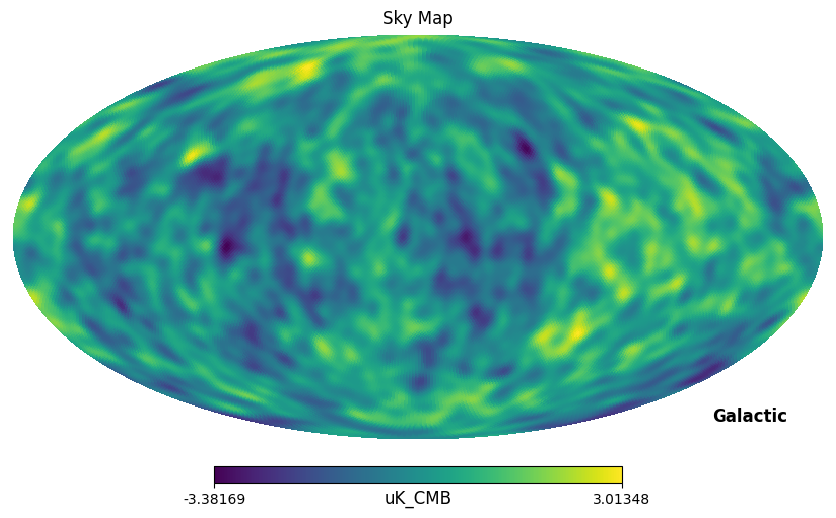

In [4]:
# Suavização gaussiana (FWHM em graus).
from radioskysims_skymap.domain.skymap.operations import SkyMapOperations

FWHM_DEG = 5.0
smoothed_data = SkyMapOperations.smooth(skymap.data, fwhm_rad=np.radians(FWHM_DEG))
smoothed = factory.create(dataset=smoothed_data, nside=NSIDE, freq_ghz=FREQ_GHZ)
smoothed

vis.plot_map(smoothed, show=False, coord="G")
fig = plt.gcf()
fig
save_figure(fig, "skymap_smoothed")


salvo: /media/barosi/RadioSkySimSuite/notebooks/plots/skymap_masked.png


PosixPath('plots/skymap_masked.png')

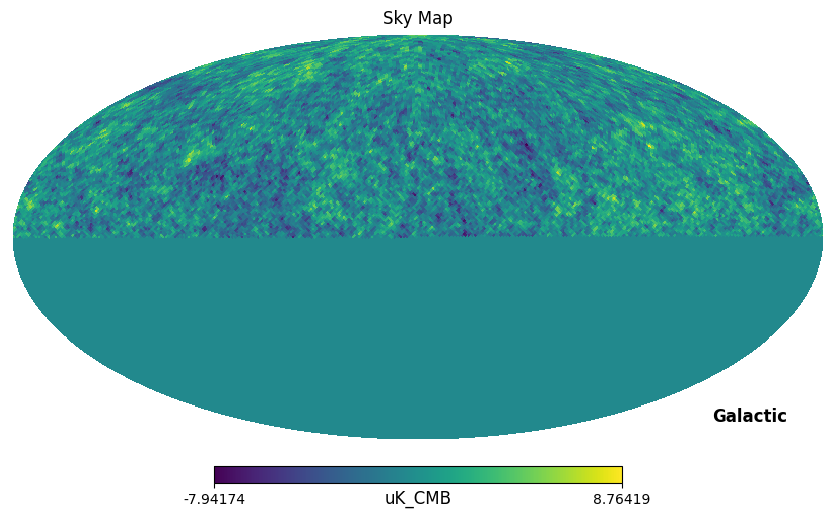

In [5]:
# Máscara binária (metade do céu) — SkyMask.apply.
from radioskysims_skymap.domain.skymap.mask import SkyMask

mask = np.ones_like(skymap.data)
mask[len(mask) // 2 :] = 0.0
masked_data = SkyMask.apply(skymap.data, mask)
masked = factory.create(dataset=masked_data, nside=NSIDE, freq_ghz=FREQ_GHZ)
masked

vis.plot_map(masked, show=False, coord="G")
fig = plt.gcf()
fig
save_figure(fig, "skymap_masked")


## 5. Análise: estatística e espectro angular

`SkyMapAnalysis` (média/RMS/min-max/Cℓ) + `SkyMapVisualizer.plot_cls`.


mean: -0.056 uK_CMB
rms : 1.921 uK_CMB
min : -8.103 | max: 8.764 uK_CMB
Cℓ (ℓ=0..4): [0.04, 0.358, 0.15, 0.171, 0.048]
salvo: /media/barosi/RadioSkySimSuite/notebooks/plots/skymap_cls.png


PosixPath('plots/skymap_cls.png')

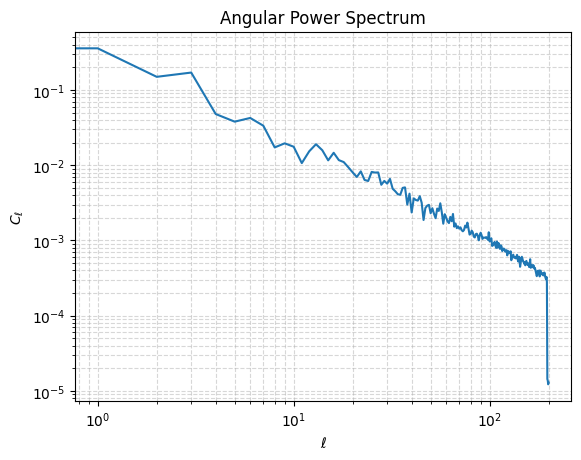

In [6]:
# Estatísticas básicas + espectro angular Cℓ.
from radioskysims_skymap.domain.skymap.analysis import SkyMapAnalysis

lo, hi = SkyMapAnalysis.min_max(skymap.data)
print("mean:", round(SkyMapAnalysis.mean(skymap.data), 3), "uK_CMB")
print("rms :", round(SkyMapAnalysis.rms(skymap.data), 3), "uK_CMB")
print("min :", round(lo, 3), "| max:", round(hi, 3), "uK_CMB")

cls = SkyMapAnalysis.angular_power_spectrum(skymap.data, lmax=200)
print("Cℓ (ℓ=0..4):", [round(float(c), 3) for c in cls[:5]])

vis.plot_cls(cls, lmax=200, show=False)
fig = plt.gcf()
fig
save_figure(fig, "skymap_cls")


## 6. I/O: FITS

`HealpySkyMapProvider` grava e relê mapas em FITS.


In [7]:
# Salva em FITS e relê (HealpySkyMapProvider).
from radioskysims_skymap.infrastructure.skymap.providers.healpy import (
    HealpySkyMapProvider,
)

provider = HealpySkyMapProvider()
path = SKYMAP_DIR / "skymap_analytic.fits"
provider.write_map(skymap, path, overwrite=True)
print("salvo:", path)

reloaded = provider.read_map(path, unit="uK_CMB", frame=FRAME)
reloaded
print("igual ao original:", np.allclose(reloaded.data, skymap.data))


setting the output map dtype to [dtype('float64')]


salvo: data/skymap/skymap_analytic.fits
igual ao original: True


## 7. API unificada — `SkyMapManager` (recomendado)

Mesmo fluxo das seções 2–6 (geração, suavização, máscara, análise e
I/O), agora encadeado através de `SkyMapManager`/`SkyMapHandle`.


In [8]:
from radioskysims_skymap import SkyMapManager

# Geração (reaproveita o espectro Cℓ definido na Seção 2) + encadeamento
# suavização → máscara → visualização, tudo em uma linha.
handle = SkyMapManager.create_map_from_coefficients(
    cls_input, nside=NSIDE, lmax=199, seed=SEED, unit="uK_CMB", freq_ghz=FREQ_GHZ
)

mask_half_sky = np.ones(handle.data.size)
mask_half_sky[len(mask_half_sky) // 2 :] = 0.0

result = handle.smooth(fwhm_deg=FWHM_DEG).mask(mask_half_sky)
result.view(show=False, title="SkyMapManager: smooth + mask")
fig = plt.gcf()
fig
save_figure(fig, "skymap_manager_chain")

stats = result.compute_statistics()
print(f"mean={stats.mean:.3f} rms={stats.rms:.3f} min={stats.min:.3f} max={stats.max:.3f} uK_CMB")

cls_out = result.compute_power_spectrum(lmax=200)
print("Cℓ (ℓ=0..4):", [round(float(c), 3) for c in cls_out[:5]])

# Persistência: arquivo avulso (FITS) e registro por chave lógica (HDF5).
manager_path = SKYMAP_DIR / "skymap_manager.fits"
result.save_to_file(manager_path, format="fits", overwrite=True)
result.register("skymap-manager-demo", overwrite=True)

reloaded = SkyMapManager.load_registered("skymap-manager-demo")
print("registro íntegro:", reloaded is not None and np.allclose(reloaded.data, result.data))


ImportError: cannot import name 'SkyMapManager' from 'radioskysims_skymap' (/media/barosi/RadioSkySimSuite/packages/radioskysims-skymap/src/radioskysims_skymap/__init__.py)